# VMamba-Tiny from scratch: full RDN training

Randomly initialized VMamba-Tiny with a new two-class head. All layers train on RDN labels; no ImageNet weights or cached features are used. Activation checkpointing reduces training memory at the cost of recomputing activations. The accelerated scan kernel is required.

**97,200 training / 10,800 validation / 3,000 released test layouts.** Read `../START_HERE.md` and run the environment notebook first. These are clean executable training cells with no saved results. Run one notebook at a time.

The target continues the pilot: class 0 if the maximum compact-response index is below 83, class 1 otherwise. This is a peak-index classification task, not bandwidth, and it is not automatically the paper's raw reflection task at 8.3 GHz. The full split is fixed across models. Validation is our adaptation of the released training set.

Hyperparameters below are starting points for a new full-data experiment. All ten scratch models start with effective batch size 128. All ten models use random initialization. Final test evaluation is enabled after training.

## Imports and portable paths

In [1]:
from __future__ import annotations
import csv
import hashlib
import json
import math
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
import timm
from tqdm.auto import tqdm
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, f1_score, roc_auc_score)

# Works when Jupyter starts in the package root or its notebooks directory.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "lab_code/runtime.py").is_file()
             and (p / "data/full_manifest.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Extract the entire package and start Jupyter inside it.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from lab_code.runtime import (
    CLASS_NAMES, FrozenClassifier, FeatureDataset, load_full_data,
    environment_info, select_device, seed_everything, precision_context,
    make_loader, layout_dataset, build_training_loaders, cache_features,
    sha256_file, atomic_json, atomic_checkpoint, save_predictions, save_history,
    plot_history, capture_rng, restore_rng, config_identity,
)
print("Package:", ROOT)


Package: /home/murat/Desktop/training_models


## Configuration

Change settings here before running subsequent cells. Changes to an existing run need a new `RUN_NAME`. All layers train from random weights; see the setup guide for the memory settings.

Training stops at **5 total epochs**, including any already completed. The original 20-epoch configuration and learning-rate schedule are retained so saved checkpoints can resume. `STOP_AFTER_EPOCH=5` controls the actual stopping limit.


In [2]:
CONFIG = {'seed': 42,
 'max_epochs': 20,
 'early_stopping_patience': 20,
 'minimum_improvement': 0.0,
 'optimizer': 'AdamW',
 'learning_rate': 0.0003,
 'weight_decay': 0.05,
 'label_smoothing': 0.0,
 'warmup_epochs': 5,
 'minimum_lr_ratio': 0.01,
 'gradient_clip_norm': 1.0,
 'precision': 'bf16',
 'num_workers': 0,
 'resume': True,
 'image_size': 224,
 'channels': 3,
 'normalization': 'imagenet',
 'train_backbone': True,
 'require_fast_vmamba': True,
 'batch_size': 4,
 'accumulation_steps': 32,
 'feature_batch_size': 4,
 'model': 'vmamba',
 'architecture': 'vmamba_tiny_s1l8',
 'initialization': 'random',
 'activation_checkpointing': True}

# For additional seeds, change CONFIG['seed'] to 43 or 44 before running later cells.
# For a changed recipe, set a distinct RUN_NAME (for example 'seed_42_lr_check').
RUN_NAME = None
REQUIRE_CUDA = True
RUN_TRAINING = True
RUN_FINAL_TEST = True  # Evaluate the validation-selected checkpoint after training.

# Total epoch cap, including saved epochs. Keep CONFIG unchanged for checkpoint resume.
STOP_AFTER_EPOCH = 5


## Device and full-data checks

Only native arrays are memory-mapped; 224/256-pixel inputs are prepared per batch. No random spatial augmentation is used.

In [3]:
if CONFIG["batch_size"] <= 0 or CONFIG["accumulation_steps"] <= 0:
    raise ValueError("Batch size and accumulation steps must be positive")
if CONFIG["max_epochs"] <= 0 or CONFIG["early_stopping_patience"] <= 0:
    raise ValueError("Epoch budget and patience must be positive")
if CONFIG["num_workers"] < 0 or not 0 <= CONFIG["warmup_epochs"] < CONFIG["max_epochs"]:
    raise ValueError("Invalid worker count or warmup length")
device = select_device(require_cuda=REQUIRE_CUDA)
seed_everything(CONFIG["seed"])
partitions, identity = load_full_data(ROOT)
mode = "from_scratch" if CONFIG.get("initialization") == "random" else "all_layers"
run_name = RUN_NAME or f"seed_{CONFIG['seed']}_{mode}_epochs_{CONFIG['max_epochs']}"
RUN_DIR = ROOT / "results" / CONFIG["model"] / run_name
print(json.dumps(environment_info(device), indent=2))
print("Full split:", {k: len(v) for k, v in partitions.items()})
print("Results:", RUN_DIR)


{
  "python": "3.12.15",
  "platform": "Linux-7.0.0-34-generic-x86_64-with-glibc2.43",
  "packages": {
    "torch": "2.12.0+cu130",
    "torchvision": "0.27.0+cu130",
    "timm": "1.0.20",
    "numpy": "2.5.2",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.11.2",
    "Pillow": "12.3.0",
    "safetensors": "0.8.0",
    "mamba-ssm": "2.2.6.post3",
    "triton": "3.7.0"
  },
  "cuda_runtime": "13.0",
  "device": "cuda",
  "gpu": "NVIDIA GeForce RTX 5050 Laptop GPU",
  "gpu_memory_bytes": 8082096128
}
Full split: {'train': 97200, 'validation': 10800, 'test': 3000}
Results: /home/murat/Desktop/training_models/results/vmamba/seed_42_from_scratch_epochs_20


## Model definition

Total parameters and trainable parameters are recorded separately.

In [4]:
class ScratchBackboneClassifier(nn.Module):
    """Train the randomly initialized backbone and two-class head together."""
    def __init__(self, backbone, feature_dim):
        super().__init__()
        self.backbone = backbone
        self.head = nn.Linear(feature_dim, 2)

    def forward(self, images):
        return self.head(self.backbone(images))

def build_vmamba_from_scratch(root, config):
    from lab_code import vmamba_official as official
    if not config["train_backbone"] or config.get("initialization") != "random":
        raise ValueError("Scratch VMamba requires random initialization and all layers trainable")
    if config["require_fast_vmamba"] and not official.WITH_SELECTIVESCAN_MAMBA:
        raise RuntimeError("VMamba selective_scan_cuda is missing; complete the kernel setup first")
    backbone = official.vmamba_tiny_s1l8(pretrained=False)
    backbone.classifier.head = nn.Identity()
    from functools import partial
    for module in backbone.modules():
        if isinstance(module, official.SS2D):
            module.forward_core = partial(module.forward_corev2, force_fp32=False,
                                          no_einsum=True, selective_scan_backend="mamba",
                                          scan_force_torch=True)
        if isinstance(module, official.VSSBlock):
            module.use_checkpoint = config.get("activation_checkpointing", True)
    return ScratchBackboneClassifier(backbone, feature_dim=backbone.num_features)

model = build_vmamba_from_scratch(ROOT, CONFIG)
model_info = {
    "architecture": CONFIG["architecture"],
    "total_parameters": sum(p.numel() for p in model.parameters()),
    "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
    "training_mode": "from_scratch",
    "physical_batch_size": CONFIG["batch_size"],
    "effective_batch_size": CONFIG["batch_size"] * CONFIG["accumulation_steps"],
    "input_size": CONFIG["image_size"], "input_channels": CONFIG["channels"],
    "pretrained": False,
}
identity["support_code_sha256"] = {
    name: sha256_file(ROOT / "lab_code" / name)
    for name in ("runtime.py", "scratch_models.py", "model_builders.py")
}
if CONFIG["model"] in ("dinov2", "vmamba"):
    identity["support_code_sha256"]["scratch_backbones.py"] = sha256_file(ROOT / "lab_code/scratch_backbones.py")
if CONFIG["model"] == "vmamba":
    identity["vmamba_source_sha256"] = sha256_file(ROOT / "lab_code/vmamba_official.py")
print(json.dumps(model_info, indent=2))


/home/murat/Desktop/training_models/lab_code/vmamba_official.py:853: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd
/home/murat/Desktop/training_models/lab_code/vmamba_official.py:868: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_bwd
/home/murat/Desktop/training_models/.venv/lib/python3.12/site-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


{
  "architecture": "vmamba_tiny_s1l8",
  "total_parameters": 29481602,
  "trainable_parameters": 29481602,
  "training_mode": "from_scratch",
  "physical_batch_size": 4,
  "effective_batch_size": 128,
  "input_size": 224,
  "input_channels": 3,
  "pretrained": false
}


## Optimizer and epoch code

This code is used directly by the training loop. Accumulation accounts for the actual number of samples in the final batch. Validation always uses evaluation mode and unsmoothed cross entropy.

In [5]:
def optimizer_and_scheduler(model, config):
    parameters = [p for p in model.parameters() if p.requires_grad]
    if config["optimizer"] == "Adam":
        optimizer = torch.optim.Adam(parameters, lr=config["learning_rate"],
                                     weight_decay=config["weight_decay"])
    elif config["optimizer"] == "AdamW":
        optimizer = torch.optim.AdamW(parameters, lr=config["learning_rate"],
                                      weight_decay=config["weight_decay"])
    else:
        raise ValueError(config["optimizer"])
    warmup, epochs = config["warmup_epochs"], config["max_epochs"]
    minimum = config["minimum_lr_ratio"]
    def multiplier(epoch):
        if warmup and epoch < warmup:
            return (epoch + 1) / warmup
        progress = min(1.0, max(0.0, (epoch - warmup) / max(1, epochs - warmup - 1)))
        return minimum + (1 - minimum) * (1 + math.cos(math.pi * progress)) / 2
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, multiplier)
    return optimizer, scheduler


In [6]:
def train_one_epoch(model, loader, optimizer, scaler, config, device):
    """Accumulate sample-weighted gradients, including the smaller final batch/window."""
    model.train()
    optimizer.zero_grad(set_to_none=True)
    criterion = nn.CrossEntropyLoss(label_smoothing=config["label_smoothing"], reduction="sum")
    total_loss = total_correct = total_samples = window_samples = 0
    for step, (images, labels, _) in enumerate(tqdm(loader, desc="Training", leave=False)):
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with precision_context(device, config["precision"]):
            logits = model(images)
            loss_sum = criterion(logits, labels)
        if not torch.isfinite(loss_sum):
            raise FloatingPointError("Non-finite training loss; no checkpoint overwritten")
        # Normalize by a fixed reference batch first, then correct for the actual
        # sample count at the update. This avoids very large FP16 scaled sums.
        scaler.scale(loss_sum / config["batch_size"]).backward()
        samples = len(labels)
        window_samples += samples
        total_samples += samples
        total_loss += loss_sum.detach().item()
        total_correct += (logits.argmax(1) == labels).sum().item()
        update = (step + 1) % config["accumulation_steps"] == 0 or step + 1 == len(loader)
        if update:
            scaler.unscale_(optimizer)
            for parameter in model.parameters():
                if parameter.grad is not None:
                    parameter.grad.mul_(config["batch_size"] / window_samples)
            if config["gradient_clip_norm"]:
                nn.utils.clip_grad_norm_(model.parameters(), config["gradient_clip_norm"],
                                         error_if_nonfinite=config["precision"] != "fp16")
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            window_samples = 0
    return {"loss": total_loss / total_samples, "accuracy": total_correct / total_samples}


In [7]:
@torch.inference_mode()
def evaluate(model, loader, device, config):
    """Evaluation-mode metrics use unsmoothed cross entropy for every model."""
    model.eval()
    total_loss = total_samples = 0
    labels_all, probabilities_all, predictions_all, sample_ids = [], [], [], []
    for images, labels, ids in tqdm(loader, desc="Evaluation", leave=False):
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with precision_context(device, config["precision"]):
            logits = model(images)
        loss = nn.functional.cross_entropy(logits.float(), labels, reduction="sum")
        probabilities = logits.float().softmax(1)[:, 1]
        if not torch.isfinite(loss) or not torch.isfinite(probabilities).all():
            raise FloatingPointError("Non-finite evaluation output")
        total_loss += loss.item()
        total_samples += len(labels)
        labels_all.extend(labels.cpu().tolist())
        probabilities_all.extend(probabilities.cpu().tolist())
        predictions_all.extend(logits.argmax(1).cpu().tolist())
        sample_ids.extend(ids)
    y = np.asarray(labels_all, dtype=np.int64)
    probability = np.asarray(probabilities_all)
    predicted = np.asarray(predictions_all, dtype=np.int64)  # argmax ties choose class zero.
    metrics = {"records": total_samples, "loss": total_loss / total_samples,
               "accuracy": float(accuracy_score(y, predicted)),
               "balanced_accuracy": float(balanced_accuracy_score(y, predicted)),
               "macro_f1": float(f1_score(y, predicted, average="macro", zero_division=0)),
               "roc_auc": float(roc_auc_score(y, probability)) if len(np.unique(y)) == 2 else None,
               "confusion_matrix": confusion_matrix(y, predicted, labels=[0, 1]).tolist(),
               "classification_report": classification_report(y, predicted, labels=[0, 1],
                   target_names=CLASS_NAMES, output_dict=True, zero_division=0)}
    return metrics, {"sample_id": sample_ids, "label": y.tolist(),
                     "probability_class_1": probability.tolist(), "prediction": predicted.tolist()}


## Training and validation loop

Choose the checkpoint solely by minimum validation loss. Save progress after each epoch and resume from the last complete epoch. The test set is never used in this function.

In [8]:
def fit(model, loaders, config, device, folder, identity, model_info):
    """Train/validate only; restore the minimum-validation-loss checkpoint on completion."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    contract = config_identity(config, identity)
    contract_path = folder / "run_config.json"
    if contract_path.exists() and json.loads(contract_path.read_text()) != contract:
        raise ValueError("This run folder has different settings/data. Use another run_name.")
    atomic_json(contract_path, contract)
    atomic_json(folder / "environment.json", environment_info(device))
    atomic_json(folder / "model_info.json", model_info)
    latest, best = folder / "last_checkpoint.pt", folder / "best_checkpoint.pt"
    if (folder / "TRAINING_COMPLETE.json").exists():
        state = torch.load(best, map_location="cpu", weights_only=True)
        if state["contract"] != contract:
            raise ValueError("Completed checkpoint identity mismatch")
        model.load_state_dict(state["model"])
        print("Training already complete; loaded the validation-selected checkpoint.")
        return json.loads((folder / "history.json").read_text())
    optimizer, scheduler = optimizer_and_scheduler(model, config)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda" and config["precision"] == "fp16")
    history, start, best_loss, best_epoch, stale = [], 0, float("inf"), 0, 0
    elapsed_before = 0.0
    if latest.exists():
        if not config["resume"]:
            raise ValueError("Existing checkpoint found. Enable resume or use another run_name.")
        state = torch.load(latest, map_location="cpu", weights_only=True)
        if state["contract"] != contract:
            raise ValueError("Resume checkpoint identity mismatch")
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        scaler.load_state_dict(state["scaler"])
        history, start = state["history"], state["epoch"]
        best_loss, best_epoch, stale = state["best_loss"], state["best_epoch"], state["stale_epochs"]
        elapsed_before = state["training_seconds"]
        restore_rng(state["rng"], loaders["train"])
        print(f"Resuming after epoch {start}; interrupted partial epochs are repeated.")
    started = time.monotonic()
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    epoch_limit = min(config["max_epochs"], STOP_AFTER_EPOCH)
    if epoch_limit <= 0 or start > epoch_limit:
        raise ValueError("Stopping limit must be positive and cannot precede saved epochs")
    atomic_json(folder / "execution_limit.json", {"stop_after_epoch": epoch_limit,
                "original_epoch_budget": config["max_epochs"], "resume_schedule_preserved": True})
    print(f"Training stops at {epoch_limit} total epochs; resuming after epoch {start}.")
    for epoch in range(start, epoch_limit):
        if stale >= config["early_stopping_patience"]:
            break
        epoch_start = time.monotonic()
        lr = optimizer.param_groups[0]["lr"]
        training = train_one_epoch(model, loaders["train"], optimizer, scaler, config, device)
        validation, _ = evaluate(model, loaders["validation"], device, config)
        scheduler.step()
        history.append({"epoch": epoch + 1, "learning_rate": lr,
                        "train_loss": training["loss"], "train_accuracy": training["accuracy"],
                        "validation_loss": validation["loss"], "validation_accuracy": validation["accuracy"],
                        "epoch_seconds": time.monotonic() - epoch_start})
        improved = validation["loss"] < best_loss - config["minimum_improvement"]
        if improved:
            best_loss, best_epoch, stale = validation["loss"], epoch + 1, 0
        else:
            stale += 1
        state = {"contract": contract, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                 "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                 "epoch": epoch + 1, "history": history, "best_loss": best_loss,
                 "best_epoch": best_epoch, "stale_epochs": stale,
                 "training_seconds": elapsed_before + time.monotonic() - started,
                 "rng": capture_rng(loaders["train"])}
        if improved:
            atomic_checkpoint(best, {"contract": contract, "model": model.state_dict(),
                                     "epoch": best_epoch, "validation_loss": best_loss})
        atomic_checkpoint(latest, state)
        save_history(folder, history)
        print(f"Epoch {epoch + 1:03d}: training {training['accuracy']:.2%}; "
              f"validation {validation['accuracy']:.2%}; val loss {validation['loss']:.5f}")
    if not best.exists():
        raise RuntimeError("No validation-selected checkpoint was created")
    selected = torch.load(best, map_location="cpu", weights_only=True)
    model.load_state_dict(selected["model"])
    # Evaluate BOTH train and validation at the SAME selected checkpoint in eval mode.
    summary = {"selection": "minimum_validation_loss", "selected_epoch": selected["epoch"],
               "epochs_completed": len(history), "epoch_limit": epoch_limit, "model_info": model_info,
               "training_seconds": elapsed_before + time.monotonic() - started,
               "peak_gpu_memory_bytes": torch.cuda.max_memory_allocated(device)
               if device.type == "cuda" else None,
               "test_evaluated": False}
    for split in ("train", "validation"):
        original_loader = loaders[split]
        ordered = make_loader(original_loader.dataset, config["batch_size"], False,
                               config["seed"], config["num_workers"], device)
        metrics, predictions = evaluate(model, ordered, device, config)
        summary[split] = metrics
        save_predictions(folder / f"{split}_predictions.csv", predictions)
    atomic_json(folder / "training_validation_metrics.json", summary)
    atomic_json(folder / "TRAINING_COMPLETE.json", {"selected_epoch": selected["epoch"],
                                                  "epochs_completed": len(history), "epoch_limit": epoch_limit, "test_evaluated": False})
    return history


## Start or resume training

All models train from images and update every layer. This cell starts real training on the computer.

In [9]:
# This is the actual training launch. It runs the FULL training/validation split.
# The test partition is not loaded into any epoch loop.
if RUN_TRAINING:
    existing_config = RUN_DIR / "run_config.json"
    if existing_config.exists() and json.loads(existing_config.read_text()) != config_identity(CONFIG, identity):
        raise ValueError("This folder has different settings/data. Choose a new RUN_NAME before feature extraction.")
    model.to(device)
    training_model, loaders, cached_features = build_training_loaders(
        model, ROOT, partitions, CONFIG, device, identity
    )
    history = fit(training_model, loaders, CONFIG, device, RUN_DIR, identity, model_info)
else:
    print("Training is disabled by RUN_TRAINING; no model was trained.")


Training already complete; loaded the validation-selected checkpoint.


## Results and accuracy/loss graphs

Curves show online training and evaluation-mode validation. Final train/validation metrics are evaluated at the same selected checkpoint.

Selected epoch: 4
train: accuracy=64.66%, balanced accuracy=64.64%, macro F1=0.6464
validation: accuracy=64.71%, balanced accuracy=64.72%, macro F1=0.6471


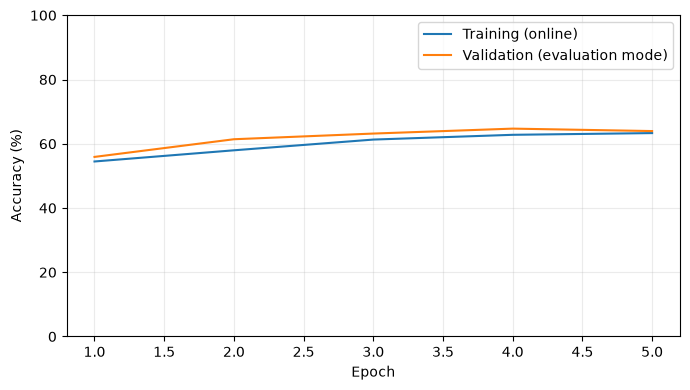

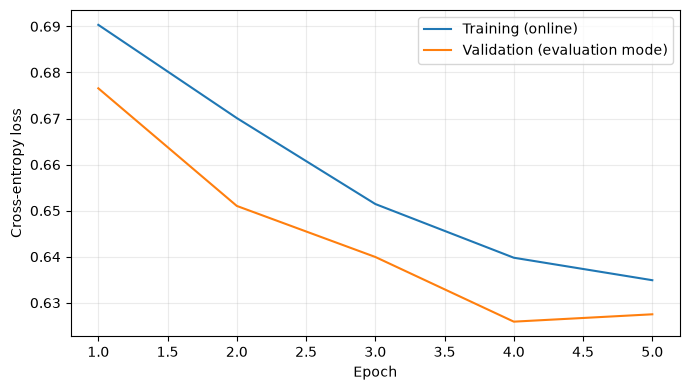

In [10]:
if (RUN_DIR / "TRAINING_COMPLETE.json").exists():
    summary = json.loads((RUN_DIR / "training_validation_metrics.json").read_text())
    print("Selected epoch:", summary["selected_epoch"])
    for split in ("train", "validation"):
        values = summary[split]
        print(f"{split}: accuracy={values['accuracy']:.2%}, "
              f"balanced accuracy={values['balanced_accuracy']:.2%}, macro F1={values['macro_f1']:.4f}")
    plot_history(RUN_DIR, show=True)
else:
    print("No completed training results yet.")


## Final held-out test

Enabled by `RUN_FINAL_TEST=True`; runs after training completes. This evaluates the selected checkpoint on all 3,000 original test layouts once, and reuses its saved result on repeated execution.

In [11]:
def evaluate_test(model, training_model, root, partitions, config, device, folder, identity, cached):
    """An explicitly called, cached final test evaluation. Never called by fit()."""
    folder = Path(folder)
    if not (folder / "TRAINING_COMPLETE.json").exists():
        raise RuntimeError("Complete training/validation selection before evaluating the test set")
    checkpoint = folder / "best_checkpoint.pt"
    checksum = sha256_file(checkpoint)
    state = torch.load(checkpoint, map_location="cpu", weights_only=True)
    if state["contract"] != config_identity(config, identity):
        raise ValueError("Test checkpoint identity mismatch")
    output = folder / "test_metrics.json"
    if output.exists():
        stored = json.loads(output.read_text())
        if stored["checkpoint_sha256"] != checksum:
            raise ValueError("Test output exists for a different checkpoint; refusing to overwrite it")
        print("Using the existing final test evaluation.")
        return stored
    training_model.load_state_dict(state["model"])
    training_model.to(device)
    rows = partitions["test"]
    if cached:
        model.backbone.to(device)
        features = cache_features(model, root, rows, "test", config, device, identity)
        model.backbone.to("cpu")
        dataset = FeatureDataset(features, rows)
    else:
        dataset = layout_dataset(root, rows, config)
    loader = make_loader(dataset, config["batch_size"], False, config["seed"], config["num_workers"], device)
    metrics, predictions = evaluate(training_model, loader, device, config)
    train_y = [int(r["label"]) for r in partitions["train"]]
    majority_label = int(np.argmax(np.bincount(train_y, minlength=2)))
    metrics["training_majority_label"] = majority_label
    metrics["training_selected_majority_baseline_accuracy"] = float(np.mean(
        np.asarray(predictions["label"]) == majority_label))
    metrics["selected_epoch"] = state["epoch"]
    metrics["checkpoint_sha256"] = checksum
    save_predictions(folder / "test_predictions.csv", predictions)
    atomic_json(output, metrics)
    fig, ax = plt.subplots(figsize=(5, 4))
    matrix = np.asarray(metrics["confusion_matrix"])
    ax.imshow(matrix, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(matrix[i, j]), ha="center", va="center")
    ax.set(xticks=[0, 1], yticks=[0, 1], xlabel="Predicted class", ylabel="True class")
    fig.tight_layout()
    fig.savefig(folder / "test_confusion_matrix.png", dpi=180)
    plt.close(fig)
    return metrics

if RUN_FINAL_TEST:
    # This cell can also be run after restarting the kernel and executing setup/model
    # cells. It does not require re-executing the training launch cell.
    cached_features = CONFIG["model"] in ("dinov2", "vmamba") and not CONFIG["train_backbone"]
    training_model = model.head if cached_features else model
    metrics = evaluate_test(model, training_model, ROOT, partitions, CONFIG, device,
                            RUN_DIR, identity, cached_features)
    print(json.dumps(metrics, indent=2))
else:
    print("Final test evaluation is disabled. Keep it disabled during tuning.")


Using the existing final test evaluation.
{
  "records": 3000,
  "loss": 0.61724882320563,
  "accuracy": 0.6533333333333333,
  "balanced_accuracy": 0.6529508303930391,
  "macro_f1": 0.6529630063013909,
  "roc_auc": 0.7176160950906914,
  "confusion_matrix": [
    [
      931,
      522
    ],
    [
      518,
      1029
    ]
  ],
  "classification_report": {
    "PeakBelow83": {
      "precision": 0.642512077294686,
      "recall": 0.6407432897453544,
      "f1-score": 0.6416264645072364,
      "support": 1453.0
    },
    "PeakAtOrAbove83": {
      "precision": 0.6634429400386848,
      "recall": 0.665158371040724,
      "f1-score": 0.6642995480955455,
      "support": 1547.0
    },
    "accuracy": 0.6533333333333333,
    "macro avg": {
      "precision": 0.6529775086666854,
      "recall": 0.6529508303930391,
      "f1-score": 0.6529630063013909,
      "support": 3000.0
    },
    "weighted avg": {
      "precision": 0.6533054255163413,
      "recall": 0.6533333333333333,
      "f1-s

## References

[SUTD-PRCM paper](https://arxiv.org/html/2203.00002) · [Dataset release](https://github.com/veya2ztn/SUTD_PRCM_dataset) · [timm](https://github.com/huggingface/pytorch-image-models) · [DINOv2](https://github.com/facebookresearch/dinov2) · [VMamba](https://github.com/MzeroMiko/VMamba)